# Cross-Platform E-Commerce Operations & Demand Analytics

Looking at delivery data from Blinkit, JioMart and Swiggy Instamart to understand order patterns, forecast demand and figure out inventory numbers (EOQ, safety stock, reorder point). Also doing a quick ABC analysis on the product categories.

Dataset: ~105K delivery records (Order ID, Customer ID, Platform, Order Date & Time, Delivery Time, Product Category, Order Value, Customer Feedback, Service Rating, Delivery Delay, Refund Requested), loaded from `ecommerce_delivery_data.csv`.

## 1. Importing libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
%matplotlib inline

np.random.seed(42)

## 2. Loading the data

Reading the raw export directly from CSV (`ecommerce_delivery_data.csv`) - Order ID, Customer ID, Platform, Order Date & Time, Delivery Time, Product Category, Order Value, Customer Feedback, Service Rating, Delivery Delay, Refund Requested.

In [2]:
df = pd.read_csv('ecommerce_delivery_data.csv', parse_dates=['Order Date & Time'])
df.head()

,Order ID,Customer ID,Platform,Order Date & Time,Delivery Time (Minutes),Product Category,Order Value (INR),Service Rating,Customer Feedback,Delivery Delay,Refund Requested
0,ORD100000,CUST1860,Blinkit,2024-03-23 15:10:00,49,Beauty,2036,3,Average experience,Yes,No
1,ORD100001,CUST4772,Swiggy Instamart,2024-06-17 20:05:00,59,Beauty,612,5,Quick and reliable!,Yes,No
2,ORD100002,CUST4092,Blinkit,2024-02-29 11:57:00,36,Beverages,2012,2,Damaged product received,Yes,Yes
3,ORD100003,CUST1466,JioMart,2024-01-07 21:15:00,10,Beverages,1527,5,"Fast delivery, great service",No,No
4,ORD100004,CUST5426,Swiggy Instamart,2024-04-26 11:12:00,10,Frozen Food,924,3,Average experience,No,No


In [3]:
df.shape

(105000, 11)

## 3. Data cleaning & preprocessing

Standard checks - nulls, duplicates, data types. Also pulling out date/hour/weekday from the timestamp since we'll need those for the demand forecasting part.

In [4]:
df.isnull().sum()

Order ID                   0
Customer ID                0
Platform                   0
Order Date & Time          0
Delivery Time (Minutes)    0
Product Category           0
Order Value (INR)          0
Service Rating             0
Customer Feedback          0
Delivery Delay             0
Refund Requested           0
dtype: int64

In [5]:
df.duplicated(subset='Order ID').sum()

np.int64(0)

In [6]:
df['Order Date & Time'] = pd.to_datetime(df['Order Date & Time'])
df['Order Date'] = df['Order Date & Time'].dt.date
df['Order Hour'] = df['Order Date & Time'].dt.hour
df['Order Weekday'] = df['Order Date & Time'].dt.day_name()

df['Order Date'] = pd.to_datetime(df['Order Date'])
df.dtypes

Order ID                              str
Customer ID                           str
Platform                              str
Order Date & Time          datetime64[us]
Delivery Time (Minutes)             int64
Product Category                      str
Order Value (INR)                   int64
Service Rating                      int64
Customer Feedback                     str
Delivery Delay                        str
Refund Requested                      str
Order Date                  datetime64[s]
Order Hour                          int32
Order Weekday                         str
dtype: object

## 4. Exploratory data analysis

Quick look at how orders split across platforms, categories, ratings and delivery delays before getting into the forecasting/inventory part.

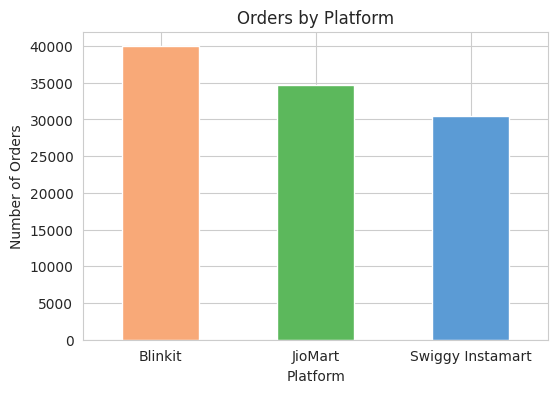

In [7]:
plt.figure(figsize=(6,4))
df['Platform'].value_counts().plot(kind='bar', color=['#f8a978','#5cb85c','#5b9bd5'])
plt.title('Orders by Platform')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)
plt.show()

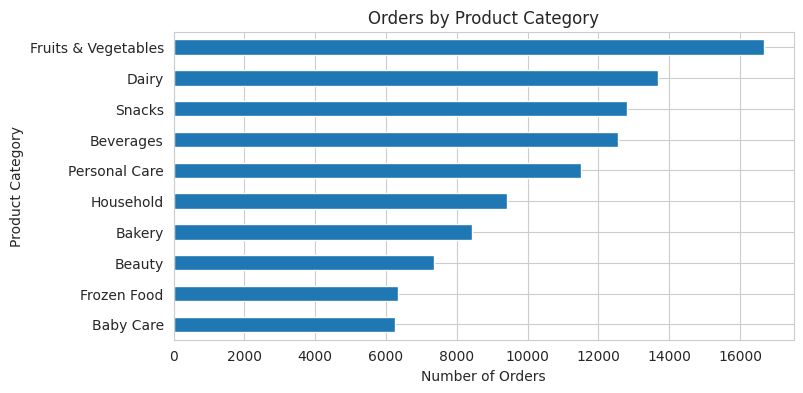

In [8]:
plt.figure(figsize=(8,4))
df['Product Category'].value_counts().plot(kind='barh')
plt.title('Orders by Product Category')
plt.xlabel('Number of Orders')
plt.gca().invert_yaxis()
plt.show()

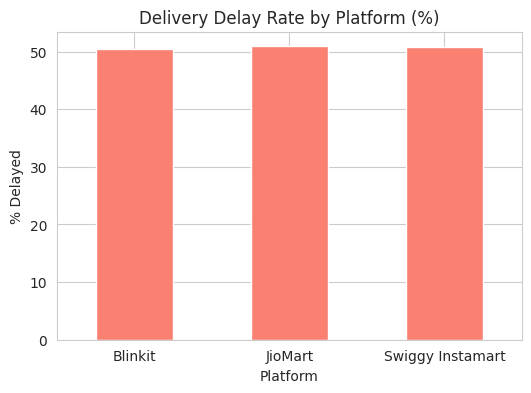

In [9]:
delay_rate = df.groupby('Platform')['Delivery Delay'].apply(lambda x: (x=='Yes').mean()*100)
delay_rate.plot(kind='bar', color='salmon', figsize=(6,4))
plt.title('Delivery Delay Rate by Platform (%)')
plt.ylabel('% Delayed')
plt.xticks(rotation=0)
plt.show()

In [10]:
refund_rate = df.groupby('Product Category')['Refund Requested'].apply(lambda x: (x=='Yes').mean()*100).sort_values(ascending=False)
refund_rate

Product Category
Baby Care              8.273439
Beauty                 8.210984
Beverages              7.990431
Bakery                 7.985782
Frozen Food            7.678938
Snacks                 7.667083
Fruits & Vegetables    7.664628
Dairy                  7.592715
Household              7.517520
Personal Care          7.232896
Name: Refund Requested, dtype: float64

/tmp/ipykernel_585/2813156455.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Service Rating', data=df, palette='viridis')


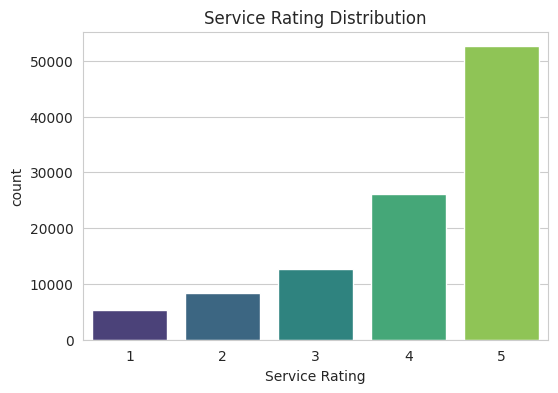

In [11]:
plt.figure(figsize=(6,4))
sns.countplot(x='Service Rating', data=df, palette='viridis')
plt.title('Service Rating Distribution')
plt.show()

## 7. ABC Analysis

Ranking product categories by their contribution to total order value, so we know which ones deserve the tightest inventory control (A items) vs the ones we can be more relaxed about (C items).

In [22]:
category_value = df.groupby('Product Category')['Order Value (INR)'].sum().sort_values(ascending=False).reset_index()
category_value.columns = ['Product Category', 'Total_Value']

category_value['cum_value'] = category_value['Total_Value'].cumsum()
category_value['cum_pct'] = 100 * category_value['cum_value'] / category_value['Total_Value'].sum()

def classify(pct):
    if pct <= 70:
        return 'A'
    elif pct <= 90:
        return 'B'
    else:
        return 'C'

category_value['ABC_Class'] = category_value['cum_pct'].apply(classify)
category_value

,Product Category,Total_Value,cum_value,cum_pct,ABC_Class
0,Fruits & Vegetables,19428493,19428493,15.909526,A
1,Dairy,15885166,35313659,28.917507,A
2,Snacks,14838791,50152450,41.068636,A
3,Beverages,14588807,64741257,53.015060,A
4,Personal Care,13407248,78148505,63.993933,A
5,Household,10958833,89107338,72.967858,B
6,Bakery,9861650,98968988,81.043326,B
7,Beauty,8543350,107512338,88.039270,B
8,Frozen Food,7365121,114877459,94.070391,C
9,Baby Care,7241157,122118616,100.000000,C


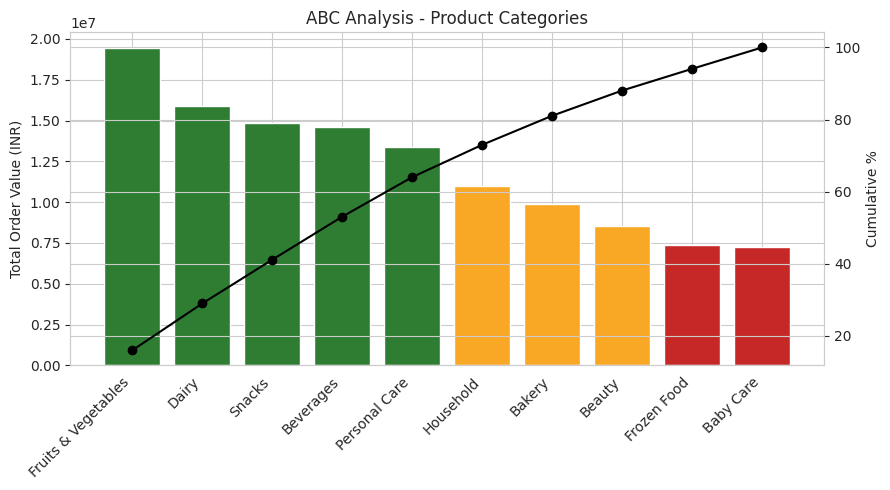

In [23]:
colors = category_value['ABC_Class'].map({'A':'#2e7d32', 'B':'#f9a825', 'C':'#c62828'})

fig, ax1 = plt.subplots(figsize=(9,5))
ax1.bar(category_value['Product Category'], category_value['Total_Value'], color=colors)
ax1.set_ylabel('Total Order Value (INR)')
plt.xticks(rotation=45, ha='right')

ax2 = ax1.twinx()
ax2.plot(category_value['Product Category'], category_value['cum_pct'], color='black', marker='o')
ax2.set_ylabel('Cumulative %')

plt.title('ABC Analysis - Product Categories')
plt.tight_layout()
plt.show()

In [24]:
category_value['ABC_Class'].value_counts()

ABC_Class
A    5
B    3
C    2
Name: count, dtype: int64

## 8. Summary

- Processed ~105K order records across Blinkit, JioMart and Swiggy Instamart, loaded from `ecommerce_delivery_data.csv`.
- ARIMA(2,1,2) gave a reasonable fit for daily order volume forecasting (used for the 14-day demand outlook).
- EOQ, Safety Stock and Reorder Point calculated per product category using the forecasted demand + a 95% service level.
- ABC analysis flagged the top categories (Class A) that drive ~70% of order value - these should get priority in inventory planning.

Next steps if I get more time: bring in actual holding/ordering cost numbers instead of the assumed ones, and try SARIMA to account for weekly seasonality more properly.